# 用holoviews和numba绘制Mandelbrot集

本文介绍如何使用holoviews的`DynamicMap`观察Mandelbrot集。首先在载入`holoviews`库之后，调用`extension('bokeh')`载入Bokeh的扩展插件，使用Bokeh作为绘图库可以动态更新绘图的内容。


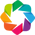

In [19]:
from numba import jit
import numpy as np
import holoviews as hv
hv.extension('bokeh') #❶

下面首先使用Numba编写快速计算Mandelbrot集的函数`create_fractal()`，它的前4个参数指定计算范围，`image`参数指定计算结果输出的数组，`iters`为最大迭代次数。

In [30]:
@jit(nopython=True)
def mandel(x, y, max_iters):
    i = 0
    c = complex(x,y)
    z = 0.0j
    for i in range(max_iters):
        z = z * z + c
        r = z.real**2 + z.imag**2
        if r >= 4:
            break
    if r > 4:
        mu = i - np.log2(0.5 * np.log2(r))
    else:
        mu = i
    return mu

@jit(nopython=True, parallel=True)
def create_fractal(min_x, max_x, min_y, max_y, image, iters):
    height = image.shape[0]
    width = image.shape[1]

    pixel_size_x = (max_x - min_x) / width
    pixel_size_y = (max_y - min_y) / height
    for x in range(width):
        real = min_x + x * pixel_size_x
        for y in range(height):
            imag = min_y + y * pixel_size_y
            color = mandel(real, imag, iters)
            image[y, x] = color

下面使用`holoviews.Image`将数组显示为图像：

In [39]:
%opts Image [width=400 height=400] (cmap="Blues_r")
arr = np.zeros((400, 400))
x, y, r = 0.27322626, 0.595153338, 0.05
create_fractal(x-r, x+r, y-r, y+r, arr, 100)
hv.Image(arr)

:Image   [x,y]   (z)

为了动态显示图像，可以使用`holoviews.DynamicMap`，它的第一个参数是返回`Image`对象的函数`make_image()`。❶该函数的两个参数`x_range`和`y_range`分别表示图像的X轴和Y轴的范围。❷使用`streams`参数将图像中的事件`streams.RangeXY`与该函数进行绑定。这样当图像的显示范围被修改时，holoviews会将新的显示范围传递给`make_image()`函数，并使用其返回值刷新图像。

In [42]:
ranges = []
def make_image(x_range, y_range): #❶
    ranges.append((x_range, y_range))
    if x_range is None or y_range is None:
        x_range = -2, 2
        y_range = -2, 2
    x0, x1 = x_range
    y0, y1 = y_range
    img = np.zeros((200, 200))
    create_fractal(x0, x1, y0, y1, img, 100)
    return hv.Image(img[::-1, :], bounds=(x0, y0, x1, y1))

hv.DynamicMap(make_image, streams=[hv.streams.RangeXY()]) #❷

:DynamicMap   []
   :Image   [x,y]   (z)